# AN6 — Recorded VLE Activity Patterns

**Status:** Controlled execution package; no outputs are embedded in the repository copy. Run cells individually, not Run All. The notebook uses the canonical runner for readiness, sequential execution, and PostgreSQL diagnostics. It describes recorded platform activity, not learning quality.


## 1. Environment setup

This cell locates the repository and imports the same canonical AN6 execution helpers used by `scripts/run_an6.py`. It does not connect to PostgreSQL.

In [1]:
# 1. Locate the repository and import the canonical AN6 orchestration functions.
from pathlib import Path
import sys
from IPython.display import display

_current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in [_current, *_current.parents]
        if (candidate / "src" / "analytics" / "db.py").is_file()
        and (candidate / "sql" / "04_analytics").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open Jupyter from the repository root or notebooks folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.run_an6 import (
    EXPECTED_RESULT_SET_COUNTS as EXPECTED,
    AN6_ANALYTICAL_TIMEOUT_MS,
    verify_read_only_preflight,
    run_an6_query,
    readiness_gate,
)

import pandas as pd
import matplotlib.pyplot as plt

query_results = {}
AN6_READINESS_PASSED = False

print("Project root:", PROJECT_ROOT)
print("Canonical AN6 runner imported: True")
print("AN6 expected result sets:", EXPECTED)


Project root: G:\OULAD-EdTech-Learning-Analytics-starter\OULAD-EdTech-Learning-Analytics
Canonical AN6 runner imported: True
AN6 expected result sets: {'AN6.01': 3, 'AN6.02': 1, 'AN6.03': 1, 'AN6.04': 1}


## 2. AN0.01 — Database identity and read-only preflight

The canonical preflight verifies the intended database and both read-only settings. The returned database identity, session settings, and elapsed time are displayed as execution evidence. No AN6 analytical query runs unless this preflight passes.

In [2]:
# 2. Run the canonical database identity/read-only preflight.
preflight = verify_read_only_preflight()
query_results["PREFLIGHT.AN0.01"] = preflight
display(preflight["data"])
assert preflight["result_set_count"] == 1
print("CONNECTION AND READ-ONLY PREFLIGHT: PASS")



AN6 — PostgreSQL connection and safety preflight
Query: sql\04_analytics\AN0.01_database_identity.sql
Elapsed seconds: 0.034
Returned result sets: 1
  database_name database_user current_schema server_version transaction_read_only default_transaction_read_only statement_timeout lock_timeout
oulad_analytics      postgres         public           18.6                    on                            on              2min           5s
database_name: PASS
transaction_read_only: PASS
default_transaction_read_only: PASS
AN6 PREFLIGHT: PASS — intended database and read-only session confirmed.



,database_name,database_user,current_schema,server_version,transaction_read_only,default_transaction_read_only,statement_timeout,lock_timeout
0,oulad_analytics,postgres,public,18.6,on,on,2min,5s


CONNECTION AND READ-ONLY PREFLIGHT: PASS


## 3. AN6.01 — Readiness and metadata

**Question:** Are all 22 course windows valid, are course-scoped VLE resource keys unique, and are registration/activity keys complete? Review all three result sets. A failed readiness gate blocks AN6.02–AN6.04.

In [3]:
# 3. Execute AN6.01 and validate all three result sets before downstream scans.
r = run_an6_query("AN6.01", max_rows=500, display_results=False)
assert r["result_set_count"] == EXPECTED["AN6.01"]
query_results["AN6.01"] = r
for item in r["result_sets"]:
    print(f"Result set {item['statement_number']}: {item['rows_displayed']} displayed rows; truncated={item['display_truncated']}")
    display(item["data"])

AN6_READINESS_PASSED = readiness_gate(r)
print("AN6.01 elapsed seconds:", r["elapsed_seconds"])



AN6.01 | sql\04_analytics\AN6.01_activity_readiness_and_metadata.sql | 13.502 seconds | 3 result set(s) | timeout=120000 ms
Result set 1: 22 displayed row(s); truncated=False
Result set 2: 1 displayed row(s); truncated=False
Result set 3: 1 displayed row(s); truncated=False
Result set 1: 22 displayed rows; truncated=False


,code_module,code_presentation,module_presentation_length,course_key_rows,valid_course_window
0,AAA,2013J,268,1,True
1,AAA,2014J,269,1,True
2,BBB,2013B,240,1,True
3,BBB,2013J,268,1,True
4,BBB,2014B,234,1,True
5,BBB,2014J,262,1,True
6,CCC,2014B,241,1,True
7,CCC,2014J,269,1,True
8,DDD,2013B,240,1,True
9,DDD,2013J,261,1,True


Result set 2: 1 displayed rows; truncated=False


,vle_rows,distinct_resource_keys,duplicate_resource_keys,excess_rows_over_distinct_resource_keys,null_resource_key_component_rows,missing_activity_type_rows,missing_week_from_rows,missing_week_to_rows,reversed_week_range_rows
0,6364,6364,0,0,0,0,5243,5243,0


Result set 3: 1 displayed rows; truncated=False


,registration_rows,distinct_registration_keys,duplicate_registration_keys,excess_registration_rows,registration_keys_without_course_window,activity_rows,activity_rows_with_null_key_component,activity_rows_without_course_window
0,32593,32593,0,0,0,10655280,0,0


AN6.01 — readiness checks
expected_22_course_presentations: PASS
valid_course_windows: PASS
unique_course_keys: PASS
unique_course_scoped_vle_resource_keys: PASS
complete_vle_resource_key_components: PASS
unique_registration_keys: PASS
registration_course_matches: PASS
complete_student_vle_key_components: PASS
student_vle_course_window_matches: PASS
Metadata completeness diagnostics (reported, not used as filters): [{'missing_activity_type_rows': 0, 'missing_week_from_rows': 5243, 'missing_week_to_rows': 5243, 'reversed_week_range_rows': 0}]
AN6.01 READINESS: PASS — downstream queries are unlocked.

AN6.01 elapsed seconds: 13.502


## 4. AN6.02 — In-course coverage and student-presentation distributions

**Question:** What share of registered student-presentations has in-course activity? How are zero-inclusive active days and resource breadth distributed? First activity day is conditional on activity being recorded.


In [4]:
# Execute AN6.02 only after the AN6.01 readiness gate has passed.
assert AN6_READINESS_PASSED, 'Run and pass the AN6.01 readiness gate before this query.'
r = run_an6_query("AN6.02", max_rows=500, display_results=False)
assert r["result_set_count"] == EXPECTED["AN6.02"]
query_results["AN6.02"] = r
display(r["result_sets"][0]["data"])
print("Elapsed seconds:", r["elapsed_seconds"])



AN6.02 | sql\04_analytics\AN6.02_in_course_student_presentation_metrics.sql | 73.25 seconds | 1 result set(s) | timeout=600000 ms
Result set 1: 88 displayed row(s); truncated=False


,code_module,code_presentation,output_section,metric,registered_denominator,observed_count,outside_window_only_count,no_recorded_activity_count,pct_or_mean,p25,median,p75,p90
0,AAA,2013J,COVERAGE,IN_COURSE_COVERAGE,383,376,2.0,5.0,98.17,NaN,NaN,NaN,NaN
1,AAA,2013J,DISTRIBUTION,ACTIVE_DAYS,383,7,NaN,NaN,84.7389033942558747,38.5,76.0,119.5,169.0
2,AAA,2013J,DISTRIBUTION,FIRST_IN_COURSE_DAY,383,376,2.0,5.0,2.4574468085106383,0.0,1.0,3.0,7.0
3,AAA,2013J,DISTRIBUTION,RESOURCE_BREADTH,383,7,NaN,NaN,58.8511749347258486,42.5,60.0,78.0,87.0
4,AAA,2014J,COVERAGE,IN_COURSE_COVERAGE,365,352,5.0,8.0,96.44,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,GGG,2014B,DISTRIBUTION,RESOURCE_BREADTH,833,67,NaN,NaN,27.6770708283313325,14.0,29.0,41.0,49.0
84,GGG,2014J,COVERAGE,IN_COURSE_COVERAGE,749,689,9.0,51.0,91.99,NaN,NaN,NaN,NaN
85,GGG,2014J,DISTRIBUTION,ACTIVE_DAYS,749,60,NaN,NaN,32.2603471295060080,8.0,27.0,46.0,68.0
86,GGG,2014J,DISTRIBUTION,FIRST_IN_COURSE_DAY,749,689,9.0,51.0,9.2119013062409289,1.0,3.0,9.0,25.0


Elapsed seconds: 73.25


## 5. AN6.03 — Temporal patterns

**Question:** How do activity rows distribute across PRE/IN/POST and fixed seven-day bins? These bins are not academic weeks.

**Execution design:** The SQL first collapses records to student-presentation × temporal bucket/period grain using GROUPING SETS. Presentation-level reach is then counted from those unique student-level groups. This removes the large composite distinct-key sort and avoids a global output sort. Boundary-day diagnostics remain separate and are restricted to four dates per presentation.


In [5]:
# Execute AN6.03 only after the AN6.01 readiness gate has passed.
assert AN6_READINESS_PASSED, 'Run and pass the AN6.01 readiness gate before this query.'
r = run_an6_query("AN6.03", max_rows=500, display_results=False)
assert r["result_set_count"] == EXPECTED["AN6.03"]
query_results["AN6.03"] = r
display(r["result_sets"][0]["data"])
print("Elapsed seconds:", r["elapsed_seconds"])



AN6.03 | sql\04_analytics\AN6.03_relative_time_patterns.sql | 94.658 seconds | 1 result set(s) | timeout=600000 ms
Result set 1: 500 displayed row(s); truncated=True


,code_module,code_presentation,output_section,bucket_label,period_index,registered_student_presentations,activity_rows,active_registered_student_presentations,unmatched_registration_activity_rows,recorded_clicks
0,AAA,2013J,TEMPORAL_BUCKET,IN_COURSE,NaN,383,170135,376,0.0,598871
1,AAA,2013J,TEMPORAL_BUCKET,PRE_COURSE,NaN,383,10847,352,0.0,49623
2,AAA,2014J,TEMPORAL_BUCKET,IN_COURSE,NaN,365,154808,352,0.0,534312
3,AAA,2014J,TEMPORAL_BUCKET,PRE_COURSE,NaN,365,14508,335,0.0,63846
4,BBB,2013B,TEMPORAL_BUCKET,IN_COURSE,NaN,1767,383528,1513,0.0,1282887
...,...,...,...,...,...,...,...,...,...,...
495,DDD,2014J,RELATIVE_7DAY_PERIOD,PERIOD_034,34.0,1803,18253,898,NaN,45270
496,DDD,2014J,RELATIVE_7DAY_PERIOD,PERIOD_035,35.0,1803,2270,366,NaN,5116
497,DDD,2014J,RELATIVE_7DAY_PERIOD,PERIOD_036,36.0,1803,1455,318,NaN,2543
498,DDD,2014J,RELATIVE_7DAY_PERIOD,PERIOD_037,37.0,1803,617,211,NaN,993


Elapsed seconds: 94.658


## 6. AN6.04 — Activity-type composition

**Question:** Which resource types contribute to in-course resource breadth and registered student-presentation reach? Missing and unmatched metadata remain explicit.


In [6]:
# Execute AN6.04 only after the AN6.01 readiness gate has passed.
assert AN6_READINESS_PASSED, 'Run and pass the AN6.01 readiness gate before this query.'
r = run_an6_query("AN6.04", max_rows=500, display_results=False)
assert r["result_set_count"] == EXPECTED["AN6.04"]
query_results["AN6.04"] = r
display(r["result_sets"][0]["data"])
print("Elapsed seconds:", r["elapsed_seconds"])



AN6.04 | sql\04_analytics\AN6.04_activity_type_resource_patterns.sql | 123.511 seconds | 1 result set(s) | timeout=600000 ms
Result set 1: 254 displayed row(s); truncated=False


,output_section,code_module,code_presentation,activity_type,registered_student_presentations,in_course_activity_rows,distinct_resources,active_student_presentations,registered_reach_pct,distinct_course_relative_days,unmatched_resource_rows,all_activity_rows,matched_resource_rows,unmatched_resource_rows_total,missing_activity_type_rows,unmatched_registration_activity_rows
0,ALL_ACTIVITY_METADATA_MATCH,AAA,2013J,ALL_TYPES,383,NaN,NaN,NaN,None,NaN,NaN,180982.0,180982.0,0.0,0.0,0.0
1,IN_COURSE_ACTIVITY_TYPE,AAA,2013J,dataplus,383,442.0,4.0,190.0,49.61,149.0,0.0,NaN,NaN,NaN,NaN,NaN
2,IN_COURSE_ACTIVITY_TYPE,AAA,2013J,forumng,383,55083.0,15.0,371.0,96.87,269.0,0.0,NaN,NaN,NaN,NaN,NaN
3,IN_COURSE_ACTIVITY_TYPE,AAA,2013J,glossary,383,102.0,2.0,60.0,15.67,76.0,0.0,NaN,NaN,NaN,NaN,NaN
4,IN_COURSE_ACTIVITY_TYPE,AAA,2013J,homepage,383,31836.0,1.0,376.0,98.17,269.0,0.0,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249,IN_COURSE_ACTIVITY_TYPE,GGG,2014J,homepage,749,22710.0,1.0,688.0,91.86,270.0,0.0,NaN,NaN,NaN,NaN,NaN
250,IN_COURSE_ACTIVITY_TYPE,GGG,2014J,oucontent,749,26634.0,26.0,656.0,87.58,248.0,0.0,NaN,NaN,NaN,NaN,NaN
251,IN_COURSE_ACTIVITY_TYPE,GGG,2014J,quiz,749,18899.0,8.0,582.0,77.70,237.0,0.0,NaN,NaN,NaN,NaN,NaN
252,IN_COURSE_ACTIVITY_TYPE,GGG,2014J,resource,749,13475.0,61.0,676.0,90.25,252.0,0.0,NaN,NaN,NaN,NaN,NaN


Elapsed seconds: 123.511


## 7. Descriptive visual summary

Charts are created only from returned SQL frames; no pre-execution figures or findings are embedded.


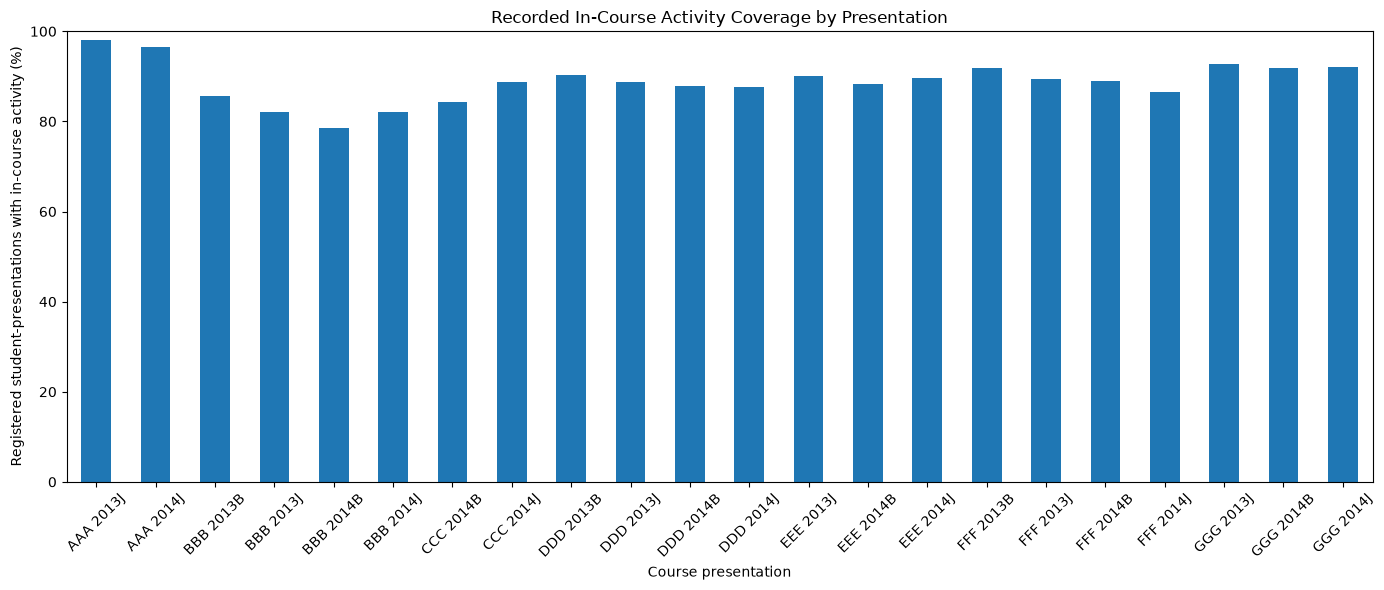

,code_module,code_presentation,output_section,metric,registered_denominator,observed_count,outside_window_only_count,no_recorded_activity_count,pct_or_mean,p25,median,p75,p90
1,AAA,2013J,DISTRIBUTION,ACTIVE_DAYS,383,7,NaN,NaN,84.7389033942558747,38.5,76.0,119.5,169.0
2,AAA,2013J,DISTRIBUTION,FIRST_IN_COURSE_DAY,383,376,2.0,5.0,2.4574468085106383,0.0,1.0,3.0,7.0
3,AAA,2013J,DISTRIBUTION,RESOURCE_BREADTH,383,7,NaN,NaN,58.8511749347258486,42.5,60.0,78.0,87.0
5,AAA,2014J,DISTRIBUTION,ACTIVE_DAYS,365,13,NaN,NaN,77.2109589041095890,31.0,64.0,117.0,154.6
6,AAA,2014J,DISTRIBUTION,FIRST_IN_COURSE_DAY,365,352,5.0,8.0,2.9346590909090909,0.0,2.0,4.0,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,GGG,2014B,DISTRIBUTION,FIRST_IN_COURSE_DAY,833,766,7.0,60.0,8.3289817232375979,1.0,3.0,9.0,23.0
83,GGG,2014B,DISTRIBUTION,RESOURCE_BREADTH,833,67,NaN,NaN,27.6770708283313325,14.0,29.0,41.0,49.0
85,GGG,2014J,DISTRIBUTION,ACTIVE_DAYS,749,60,NaN,NaN,32.2603471295060080,8.0,27.0,46.0,68.0
86,GGG,2014J,DISTRIBUTION,FIRST_IN_COURSE_DAY,749,689,9.0,51.0,9.2119013062409289,1.0,3.0,9.0,25.0


In [8]:
# 1. Plot in-course activity coverage using an explicitly numeric series.
if "AN6.02" in query_results:
    frame = query_results["AN6.02"]["result_sets"][0]["data"].copy()

    cov = frame.loc[
        frame["output_section"].eq("COVERAGE")
    ].copy()

    if not cov.empty:
        # PostgreSQL NUMERIC values may arrive as Decimal/object in pandas.
        cov["coverage_pct"] = pd.to_numeric(
            cov["pct_or_mean"],
            errors="coerce"
        )

        # Verify that all expected coverage values are numeric.
        invalid_values = cov["coverage_pct"].isna().sum()

        if invalid_values:
            raise ValueError(
                f"AN6.02 coverage contains {invalid_values} "
                "missing or non-numeric percentage values."
            )

        cov["presentation"] = (
            cov["code_module"].astype(str)
            + " "
            + cov["code_presentation"].astype(str)
        )

        cov = cov.sort_values(
            ["code_module", "code_presentation"]
        )

        ax = cov.plot(
            x="presentation",
            y="coverage_pct",
            kind="bar",
            legend=False,
            figsize=(14, 6),
            title="Recorded In-Course Activity Coverage by Presentation"
        )

        ax.set_ylabel(
            "Registered student-presentations with in-course activity (%)"
        )
        ax.set_xlabel("Course presentation")
        ax.set_ylim(0, 100)
        ax.tick_params(axis="x", rotation=45)

        plt.tight_layout()
        plt.show()

    # Display the zero-inclusive distributions.
    distributions = frame.loc[
        frame["output_section"].eq("DISTRIBUTION")
    ].copy()

    display(distributions)

## 8. Review checklist

- Verify result-set counts and truncation/runtime metadata.
- Reconcile registration denominators and PRE/IN/POST activity rows.
- Review missing/unmatched VLE metadata.
- Do not interpret missing VLE rows as absence of learning or negative course-relative days as pre-registration activity.
- No composite score, threshold, outcome claim, or predictive feature is approved in AN6.
